IMPORT MY PROJECT LIBRARIES

In [1]:
import pandas as pd 
import numpy as np

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

CREATE MY AI TRAINING DATASET

In [3]:
data = {
    "message": [
        "Congraculations! you have won a free iphone",
        "Call me when you get home",
        "You have won $1000. claim your prize now",
        "Are we having the meeting tomorrow?",
        "Free entry into a cash prize competition",
        "Please send the assignment",
        "URGENT! You have won a lottery. Claim your reward",
        "I will see you at the school tomorrow",
        "You have been selected for a free gift card",
        "Can you help me with my homework?",
        "Win a free vacation to Bahamas! Click here to claim",
        "Your meeting scheduled is by 10 AM tomorrow. Please be on time",
        "Click here to claim your cash prize now",
        "Good morning, how are you doing today?",
        "Congratulations! you won a lottery tickets",
        "Please call me later when you are free",
        "Get free money now by clicking this link",
        "i am on my way to the office, will be there in 10 minutes",
        "Claim your mobile phone now for free by clicking this link",
        "Thank for your help with the project, I really appreciate it"
    ],
    
    "label": [
        "Spam",
        "Ham",
        "Spam",
        "Ham",
        "Spam",
        "Ham",
        "Spam",
        "Ham",
        "Spam",
        "Ham",
        "Spam",
        "Ham",
        "Spam",
        "Ham",
        "Spam",
        "Ham",
        "Spam",
        "Ham",
        "Spam",
        "Ham"
    ]
    
}    

df = pd.DataFrame(data)
df

,message,label
0,Congraculations! you have won a free iphone,Spam
1,Call me when you get home,Ham
2,You have won $1000. claim your prize now,Spam
3,Are we having the meeting tomorrow?,Ham
4,Free entry into a cash prize competition,Spam
5,Please send the assignment,Ham
6,URGENT! You have won a lottery. Claim your reward,Spam
7,I will see you at the school tomorrow,Ham
8,You have been selected for a free gift card,Spam
9,Can you help me with my homework?,Ham


SPLIT MY DATASET INTO TRAINING AND TESTING DATA


In [4]:
X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set size:", len(X_train))
print("Test set size:", len(X_test))

Training set size: 16
Test set size: 4


CONVERT TEXT INTO NUMBER

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()

X_train_vectorizer = vectorizer.fit_transform(X_train)
X_test_vectorizer = vectorizer.transform(X_test)

print("Shape of training data:", X_train_vectorizer.shape)
print("Shape of test data:", X_test_vectorizer.shape)

Shape of training data: (16, 72)
Shape of test data: (4, 72)


TRAINING MY AI MODEL

In [6]:
from sklearn.naive_bayes import MultinomialNB

In [7]:
model = MultinomialNB()

In [8]:
model.fit(X_train_vectorizer, y_train)
print("Ai model trained successfully")

Ai model trained successfully


MAKING PREDICTION IN OUR AI MODEL

In [9]:
y_pred = model.predict(X_test_vectorizer)

print("Ai predictions")
print(y_pred)

Ai predictions
['Ham' 'Ham' 'Spam' 'Spam']


EVALUATE MY AI MODEL

In [10]:
from sklearn.metrics import accuracy_score

In [11]:
Accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", Accuracy * 100, "%")

Model Accuracy: 100.0 %


CONFUSION MATRIX

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [13]:
import matplotlib.pyplot as plt

In [14]:
cm = confusion_matrix(y_test, y_pred, labels=["Ham", "Spam"])

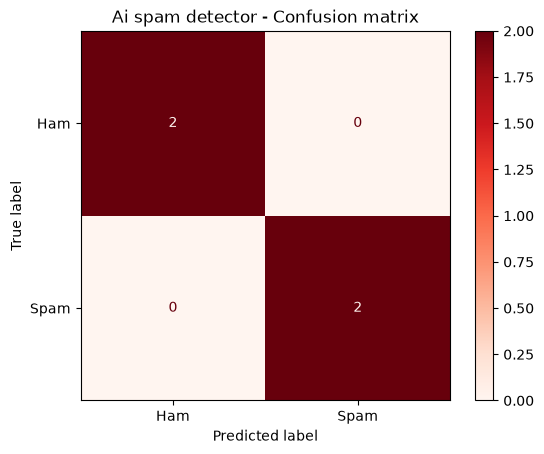

In [15]:
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=("Ham", "Spam")
)

display.plot(cmap="Reds")
plt.title("Ai spam detector - Confusion matrix")
plt.show()

TESTING MY MODEL WITH MY OWN MESSAGE

In [16]:
new_message = ["Congratulation! you have won  free cash, claim your prize now by clicking on the link below!!"]

new_message_vectorized = vectorizer.transform(new_message)

prediction = model.predict(new_message_vectorized)

print("Message:", new_message[0])
print("Ai Prediction:", prediction[0])

Message: Congratulation! you have won  free cash, claim your prize now by clicking on the link below!!
Ai Prediction: Spam


In [17]:
new_message = ["Hello, how are you?.. i just wanted to check in and see how you are doing. Hope everything is going well for you. Let's catch up soon!"]

new_message_vectorized = vectorizer.transform(new_message)

prediction = model.predict(new_message_vectorized)

print("Message:", new_message[0])
print("Ai Prediction:", prediction[0])

Message: Hello, how are you?.. i just wanted to check in and see how you are doing. Hope everything is going well for you. Let's catch up soon!
Ai Prediction: Ham


In [18]:
new_message = ["Congratulations! you have won a free car, claim your prize now by clicking on the link below!!"]

new_message_vectorized = vectorizer.transform(new_message)

prediction = model.predict(new_message_vectorized)

print("Message:", new_message[0])
print("Ai Prediction:", prediction[0])

Message: Congratulations! you have won a free car, claim your prize now by clicking on the link below!!
Ai Prediction: Spam


In [19]:
new_message = ["Hello, i am on my way to the office, will be there in 10 minutes"]

new_message_vectorized = vectorizer.transform(new_message)

prediction = model.predict(new_message_vectorized)

print("Message:", new_message[0])
print("Ai Prediction:", prediction[0])

Message: Hello, i am on my way to the office, will be there in 10 minutes
Ai Prediction: Ham


BUILD A REUSABLE SPAM DETECTOR

In [20]:
def check_message(message):
    new_message_vectorized = vectorizer.transform([message])
    prediction = model.predict(new_message_vectorized)
    
    print("Message:", message)
    print("Ai Prediction:", prediction[0])
    
check_message("You have won a free trip to Paris! Click here to claim your prize now!")    

Message: You have won a free trip to Paris! Click here to claim your prize now!
Ai Prediction: Spam


In [21]:
def check_message(message):
    new_message_vectorized = vectorizer.transform([message])
    prediction = model.predict(new_message_vectorized)
    
    print("Message:", message)
    print("Ai Prediction:", prediction[0])
    
check_message("Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!")

Message: Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!
Ai Prediction: Ham


MAKE YOUR AI SPAM DETECTOR INTERACTIVE

In [22]:
while True:
    message = input("Enter a message to check if it's spam or not (or type 'exit' to quit): ")
    if message.lower() == 'exit':
        print("Thank you for using the Ai spam detector. Goodbye!")
        break
    check_message(message)
    print("__________________")

Thank you for using the Ai spam detector. Goodbye!


IMPROVE MY AI MODDEL

In [23]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         Ham       1.00      1.00      1.00         2
        Spam       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



SAVE MY TRAINED AI MODEL

In [24]:
import joblib

In [25]:
joblib.dump(vectorizer, "spam_vectorizer.pkl")
joblib.dump(model, "spam_detector_model.pkl")
print("Ai model and vectorizer saved successfully!")

Ai model and vectorizer saved successfully!


LOAD MY SAVED AI MODEL

In [26]:
import joblib
loaded_model = joblib.load("spam_detector_model.pkl")
loaded_vectorizer = joblib.load("spam_vectorizer.pkl")
print("Ai model loaded successfully")

Ai model loaded successfully


TEST MY AI LOADED MODEL

In [27]:
test_message = ["Congratulation! you have won a free iphone and a wrist watch."]

message_vectorized = loaded_vectorizer.transform(test_message)

prediction = loaded_model.predict(message_vectorized)

print("Message:", test_message[0])
print("prediction:", prediction[0])

Message: Congratulation! you have won a free iphone and a wrist watch.
prediction: Spam


In [28]:
test_message = ["Hello! how are you doing? hope you are having a nice day today."]

message_vectorized = loaded_vectorizer.transform(test_message)

prediction = loaded_model.predict(message_vectorized)

print("Message:", test_message[0])
print("prediction:", prediction[0])

Message: Hello! how are you doing? hope you are having a nice day today.
prediction: Ham


In [29]:
import ipywidgets as widgets

CONNECT MY INTERFACE TO MY AI MODEL

In [30]:
import ipywidgets as widgets
from IPython.display import display, clear_output


message_input = widgets.Textarea(
    placeholder="Type your message here...",
    description="Message:",
    layout=widgets.Layout(width="500px", height="100px")
)

check_button = widgets.Button(
    description="Check Message",
    button_style="success"
)


output = widgets.Output()


def check_button_clicked(b):
    with output:
        clear_output(wait=True)

        message = message_input.value.strip()

        if message:
            message_vectorized = loaded_vectorizer.transform([message])
            prediction = loaded_model.predict(message_vectorized)

            print("Your Message:", message)
            print("AI Prediction:", prediction[0])
        else:
            print("Please enter a message!")


check_button.on_click(check_button_clicked)


display(message_input, check_button, output)

Textarea(value='', description='Message:', layout=Layout(height='100px', width='500px'), placeholder='Type you…

Button(button_style='success', description='Check Message', style=ButtonStyle())

Output()

ADDING PREDICTION CONFIDENCE

In [31]:
message = ["Congratulations! you have won a free iphone and a wrist watch."]
message_vectorized = loaded_vectorizer.transform(message)
prediction = loaded_model.predict(message_vectorized)
probability = loaded_model.predict_proba(message_vectorized)
print("Prediction:", prediction[0])
print("Confidence:", round(max(probability[0]) * 100, 2), "%")

Prediction: Spam
Confidence: 79.42 %


In [32]:
message = ["Hello! how are you doing? hope you had a wonderful sleep."]
message_vectorized = loaded_vectorizer.transform(message)
prediction = loaded_model.predict(message_vectorized)
probability = loaded_model.predict_proba(message_vectorized)
print("Prediction:", prediction[0])
print("Confidence:", round(max(probability[0]) * 100, 2), "%")

Prediction: Ham
Confidence: 53.88 %


BUILD A SMARTER MESSAGE TESTER FOR MY MODEL

In [33]:
def detect_spam(message):
    
    message_vectorized = loaded_vectorizer.transform([message])
    prediction = loaded_model.predict(message_vectorized)
    probability = loaded_model.predict_proba(message_vectorized)
    
    confidence = max(probability[0]) * 100
    
    print("Message:", message)
    print("Prediction:", prediction[0])
    print("Confidence:", round(confidence, 2), "%")
    
detect_spam("Congratulations! you have won a free iphone and a wrist watch.")    

Message: Congratulations! you have won a free iphone and a wrist watch.
Prediction: Spam
Confidence: 79.42 %


In [34]:
def detect_spam(message):
    
    message_vectorized = loaded_vectorizer.transform([message])
    prediction = loaded_model.predict(message_vectorized)
    probability = loaded_model.predict_proba(message_vectorized)
    
    confidence = max(probability[0]) * 100
    
    print("Message:", message)
    print("Prediction:", prediction[0])
    print("Confidence:", round(confidence, 2), "%")
    
detect_spam("Hello! how are you doing? hope you had a wonderful sleep.")

Message: Hello! how are you doing? hope you had a wonderful sleep.
Prediction: Ham
Confidence: 53.88 %


ALLOW USER TO ENTER THEIR OWN MESSAGE

In [35]:
user_input = input("Enter a message to check if it's spam or not: ")
detect_spam(user_input)

Message: exit
Prediction: Ham
Confidence: 50.0 %


ALLOW CONTINOUS MESSAGE DETECTION

In [36]:
while True:
    
    user_input = input("Enter a message to check if it's spam or not (or type 'exit' to quit): ")
    if user_input.lower() == 'exit':
        print("Spam detector closed. Thank you for using the Ai spam detector. Goodbye!")
        break
    detect_spam(user_input)
    print("__________________")

Spam detector closed. Thank you for using the Ai spam detector. Goodbye!


IMPROVE MY MODEL USER INTERFACE

In [37]:
def detect_spam(message):
    message_vectorized = loaded_vectorizer.transform([message])
    prediction = loaded_model.predict(message_vectorized)
    probability = loaded_model.predict_proba(message_vectorized)
    confidence = max(probability[0]) * 100
    
    print("\n==========SPAM DETECTOR================")
    print("Message:", message)
    
    if prediction[0] == "spam":
        print("Result: SPAM MESSAGE")
        
    else:
        print("Result: NOT SPAM MESSAGE")    
    
    print("Confidence:", round(confidence, 2), "%")
    
    print("========================================\n")

In [38]:
detect_spam("Hello! how are you doing? hope you had a wonderful sleep.")


==========SPAM DETECTOR================
Message: Hello! how are you doing? hope you had a wonderful sleep.
Result: NOT SPAM MESSAGE
Confidence: 53.88 %



In [39]:
detect_spam("Congratulations! you have won a free iphone and a wrist watch.")


==========SPAM DETECTOR================
Message: Congratulations! you have won a free iphone and a wrist watch.
Result: NOT SPAM MESSAGE
Confidence: 79.42 %



ADD ERROR HANDLING TO MY MODEL

In [40]:
def detect_spam(message):
    
    if not message.strip():
        print("Error: Empty message provided. Please enter a valid message.")
        return
    
    message_vectorized = loaded_vectorizer.transform([message])
    prediction = loaded_model.predict(message_vectorized)
    probability = loaded_model.predict_proba(message_vectorized)
    confidence = max(probability[0]) * 100
    
    print("\n==========SPAM DETECTOR================")
    print("Message:", message)
    
    if prediction[0] == "spam":
        print("Result: SPAM MESSAGE")
        
    else:
        print("Result: NOT SPAM MESSAGE")    
    
    print("Confidence:", round(confidence, 2), "%")
    
    print("========================================\n")

In [41]:
detect_spam("")

Error: Empty message provided. Please enter a valid message.


ADD A MESSAGE FEATURE IN MY MODEL HISTORY

In [42]:
message_history =[]
def check_message(message):
    detect_spam(message)
    message_history.append(message)

In [43]:
check_message("Hello! how are you doing? hope you had a wonderful sleep.")



==========SPAM DETECTOR================
Message: Hello! how are you doing? hope you had a wonderful sleep.
Result: NOT SPAM MESSAGE
Confidence: 53.88 %



In [44]:
check_message("Congratulations! you have won a free iphone and a wrist watch.")


==========SPAM DETECTOR================
Message: Congratulations! you have won a free iphone and a wrist watch.
Result: NOT SPAM MESSAGE
Confidence: 79.42 %



In [45]:
check_message("You have won a free trip to Paris! Click here to claim your prize now!")


==========SPAM DETECTOR================
Message: You have won a free trip to Paris! Click here to claim your prize now!
Result: NOT SPAM MESSAGE
Confidence: 80.68 %



In [46]:
check_message("Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!")


==========SPAM DETECTOR================
Message: Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!
Result: NOT SPAM MESSAGE
Confidence: 54.02 %



In [47]:
check_message("Claim your mobile phone now for free by clicking this link")


==========SPAM DETECTOR================
Message: Claim your mobile phone now for free by clicking this link
Result: NOT SPAM MESSAGE
Confidence: 81.38 %



In [48]:
print("Message History:")
for message in message_history:
    print("-", message) 

Message History:
- Hello! how are you doing? hope you had a wonderful sleep.
- Congratulations! you have won a free iphone and a wrist watch.
- You have won a free trip to Paris! Click here to claim your prize now!
- Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!
- Claim your mobile phone now for free by clicking this link


SAVE PREDICTION IN MESSAGE HISTORY

In [49]:
def detect_spam(message):
    if not message.strip():
        print("Error: Please enter a message.")
        return None
    message_vector = vectorizer.transform([message])  
    prediction  = model.predict(message_vector)[0]
    probability = model.predict_proba(message_vector)
    confidence = round(max(probability[0]) * 100, 2)
    
    print("Message:", message)
    print("prediction:", prediction)
    print("Confidence:", confidence, "%")
    
    return prediction, confidence

In [50]:
message_history =[]
def check_message(message):
    result = detect_spam(message)

    if result is not None:
        
        prediction, confidence = result
        
        message_history.append({
            "Message": message,
            "Prediction": prediction,
            "Confidence": confidence,
        })



In [51]:
check_message("Hello! how are you doing? hope you had a wonderful sleep.")

check_message("Congratulations! you have won a free iphone and a wrist watch.")

check_message("You have won a free trip to Paris! Click here to claim your prize now!")

check_message("Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!")

check_message("Claim your mobile phone now for free by clicking this link")

Message: Hello! how are you doing? hope you had a wonderful sleep.
prediction: Ham
Confidence: 53.88 %
Message: Congratulations! you have won a free iphone and a wrist watch.
prediction: Spam
Confidence: 79.42 %
Message: You have won a free trip to Paris! Click here to claim your prize now!
prediction: Spam
Confidence: 80.68 %
Message: Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!
prediction: Ham
Confidence: 54.02 %
Message: Claim your mobile phone now for free by clicking this link
prediction: Spam
Confidence: 81.38 %


In [52]:
for record in message_history:
    print(record)

{'Message': 'Hello! how are you doing? hope you had a wonderful sleep.', 'Prediction': np.str_('Ham'), 'Confidence': np.float64(53.88)}
{'Message': 'Congratulations! you have won a free iphone and a wrist watch.', 'Prediction': np.str_('Spam'), 'Confidence': np.float64(79.42)}
{'Message': 'You have won a free trip to Paris! Click here to claim your prize now!', 'Prediction': np.str_('Spam'), 'Confidence': np.float64(80.68)}
{'Message': "Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!", 'Prediction': np.str_('Ham'), 'Confidence': np.float64(54.02)}
{'Message': 'Claim your mobile phone now for free by clicking this link', 'Prediction': np.str_('Spam'), 'Confidence': np.float64(81.38)}


RECORD MY MODEL PREDICTION HISTORY

In [53]:
message_history = []

def check_message(message):
    message_vector = vectorizer.transform([message])
    prediction = model.predict(message_vector)[0]
    probability = model.predict_proba(message_vector)
    confidence = round(max(probability[0]) * 100, 2)
    
    record = {
        "Message": message,
        "Prediction": prediction,
        "Confidence": confidence
    }
    
    message_history.append(record)
    return record

In [54]:
check_message("Congratulations! you have won a free iphone and a wrist watch.")

{'Message': 'Congratulations! you have won a free iphone and a wrist watch.',
 'Prediction': np.str_('Spam'),
 'Confidence': np.float64(79.42)}

In [55]:
check_message("Hello! how are you doing? hope you had a wonderful sleep.")


{'Message': 'Hello! how are you doing? hope you had a wonderful sleep.',
 'Prediction': np.str_('Ham'),
 'Confidence': np.float64(53.88)}

In [56]:
check_message("Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!")

{'Message': "Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!",
 'Prediction': np.str_('Ham'),
 'Confidence': np.float64(54.02)}

In [57]:
check_message("You have won a free trip to Paris! Click here to claim your prize now!")

{'Message': 'You have won a free trip to Paris! Click here to claim your prize now!',
 'Prediction': np.str_('Spam'),
 'Confidence': np.float64(80.68)}

In [58]:
check_message("Claim your mobile phone now for free by clicking this link")

{'Message': 'Claim your mobile phone now for free by clicking this link',
 'Prediction': np.str_('Spam'),
 'Confidence': np.float64(81.38)}

In [59]:
for record in message_history:
    print(record)  

{'Message': 'Congratulations! you have won a free iphone and a wrist watch.', 'Prediction': np.str_('Spam'), 'Confidence': np.float64(79.42)}
{'Message': 'Hello! how are you doing? hope you had a wonderful sleep.', 'Prediction': np.str_('Ham'), 'Confidence': np.float64(53.88)}
{'Message': "Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!", 'Prediction': np.str_('Ham'), 'Confidence': np.float64(54.02)}
{'Message': 'You have won a free trip to Paris! Click here to claim your prize now!', 'Prediction': np.str_('Spam'), 'Confidence': np.float64(80.68)}
{'Message': 'Claim your mobile phone now for free by clicking this link', 'Prediction': np.str_('Spam'), 'Confidence': np.float64(81.38)}


SAVING MY MODEL PREDICTION HISTORY PERMENENTLY

In [60]:
import pandas as pd

history_df = pd.DataFrame(message_history)

history_df.to_csv("spam_detection_history.csv", index=False)

loaded_history = pd.read_csv("spam_detection_history.csv")

print("Prediction history saved to spam_detection_history.csv successfully.")

Prediction history saved to spam_detection_history.csv successfully.


LOAD MY MODEL SAVED PREDICTION HISTORY

In [61]:
import pandas as pd

history_df.to_csv("spam_detection_history.csv", index=False)

loaded_history = pd.read_csv("spam_detection_history.csv")

print(loaded_history.to_string())

                                                                                         Message Prediction  Confidence
0                                 Congratulations! you have won a free iphone and a wrist watch.       Spam       79.42
1                                      Hello! how are you doing? hope you had a wonderful sleep.        Ham       53.88
2  Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!        Ham       54.02
3                         You have won a free trip to Paris! Click here to claim your prize now!       Spam       80.68
4                                     Claim your mobile phone now for free by clicking this link       Spam       81.38


COUNT SPAM AND NON-SPAM IN MY MODEL

In [62]:
print("Total message:", len(loaded_history))

print("Spam message:",
      (loaded_history ["Prediction"] == "Spam").sum())
    
print("Not-spam message:",
      (loaded_history ["Prediction"] == "Ham").sum())
        

Total message: 5
Spam message: 3
Not-spam message: 2


CALCULATE SPAM DETECTION STATISTICS

In [63]:
total_messages = len(loaded_history)

spam_count = (loaded_history["Prediction"] == "Spam").sum()

Ham_count = (loaded_history["Prediction"] == "Ham").sum()

spam_percentage = (spam_count / total_messages) * 100

ham_percentage = (Ham_count / total_messages) * 100

print("========SPAM DETECTION STATISTICS=========")

print("Total message:", total_messages)

print("Spam message:", round(spam_percentage, 2), "%")
      
print("Not spam message:", round(ham_percentage, 2), "%")

print("==========================================")

========SPAM DETECTION STATISTICS=========
Total message: 5
Spam message: 60.0 %
Not spam message: 40.0 %


In [64]:
print("Total records:", len(loaded_history))

print("\nComplete prediction history:")

print(loaded_history.to_string())

print("\nPrediction counts:")

print(loaded_history["Prediction"].value_counts())

Total records: 5

Complete prediction history:
                                                                                         Message Prediction  Confidence
0                                 Congratulations! you have won a free iphone and a wrist watch.       Spam       79.42
1                                      Hello! how are you doing? hope you had a wonderful sleep.        Ham       53.88
2  Hello, how are you doing today? I hope everything is going well for you. Let's catch up soon!        Ham       54.02
3                         You have won a free trip to Paris! Click here to claim your prize now!       Spam       80.68
4                                     Claim your mobile phone now for free by clicking this link       Spam       81.38

Prediction counts:
Prediction
Spam    3
Ham     2
Name: count, dtype: int64


In [65]:
print(loaded_history["Prediction"].value_counts())

Prediction
Spam    3
Ham     2
Name: count, dtype: int64


VISUALIZE MY MODEL SPAM DETECTION STATISTICS

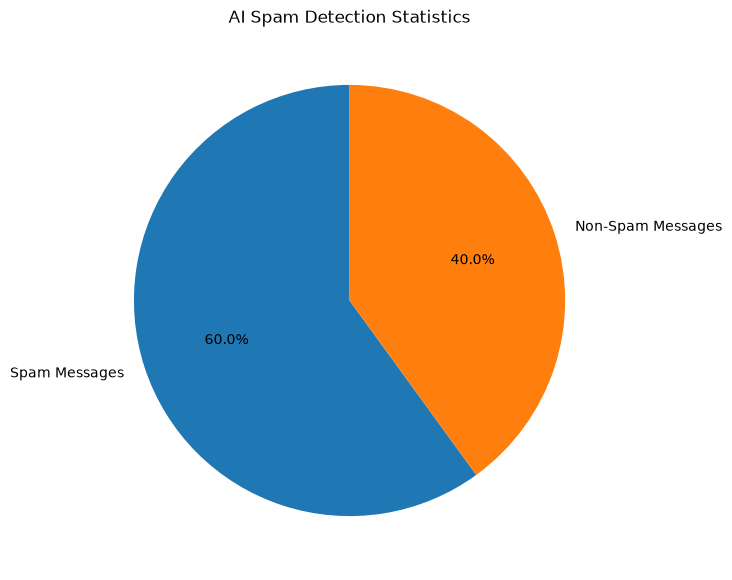

In [66]:
import matplotlib.pyplot as plt

spam_count = (loaded_history["Prediction"] == "Spam").sum()

ham_count = (loaded_history["Prediction"] == "Ham").sum()

labels = ["Spam Messages", "Non-Spam Messages"]

sizes = [spam_count, ham_count]

plt.figure(figsize=(7, 7))

plt.pie(
    sizes,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("AI Spam Detection Statistics")

plt.savefig("spam_detection_statistics.png", dpi=300, bbox_inches="tight")

plt.show()

SAVED MY AI TRAINED MODEL

In [67]:
import joblib

In [68]:
joblib.dump(vectorizer, "spam_vectorizer.pkl")

joblib.dump(model, "spam_detector_model.pkl")

print("Ai model saved successfully!")

print("vectorizer saved successfully.")

Ai model saved successfully!
vectorizer saved successfully.


LOAD MY AI SAVED MODEL

In [69]:
loaded_model = joblib.load("spam_detector_model.pkl")

loaded_vectorizer = joblib.load("spam_vectorizer.pkl")

print("Ai model loaded successfully.")
print("vectorizer loaded successfully.")

Ai model loaded successfully.
vectorizer loaded successfully.


In [70]:
test_message = ["Congratulations! You won a free prize!"]

message_vector = loaded_vectorizer.transform(test_message)

prediction = loaded_model.predict(message_vector)

probability = loaded_model.predict_proba(message_vector)

print("Prediction:", prediction[0])

print("Model Classes:", loaded_model.classes_)

print("Prediction Probabilities:", probability[0])

Prediction: Spam
Model Classes: ['Ham' 'Spam']
Prediction Probabilities: [0.25140913 0.74859087]


In [71]:
test_message = ["Hello, how are you?"]

message_vector = loaded_vectorizer.transform(test_message)

prediction = loaded_model.predict(message_vector)

probability = loaded_model.predict_proba(message_vector)

print("Prediction:", prediction[0])

print("Model Classes:", loaded_model.classes_)

print("Prediction Probabilities:", probability[0])

Prediction: Ham
Model Classes: ['Ham' 'Spam']
Prediction Probabilities: [0.58634755 0.41365245]


REUSABLE SPAM DETECTION FUNCTION

In [72]:
def detect_spam(message):
    message_vector =  vectorizer.transform([message])
    prediction = model.predict(message_vector)
    probability = model.predict_proba(message_vector)
    confidence = max(probability[0]) * 100
    
    if prediction[0] == 1:
        result = "SPAM" 
        
    else:
        result = "Ham" 
        
    print("Message:", message)
    print("Prediction:", prediction)
    print("Confidence:", round(confidence, 2), "%")        

TEST MY MODEL SPAM DETECTION FUNCTION

In [73]:
detect_spam("Congratulation! you have won a free iphone, click here to claim your reward.")

Message: Congratulation! you have won a free iphone, click here to claim your reward.
Prediction: ['Spam']
Confidence: 81.55 %


In [74]:
detect_spam("Hello! moses i just wanted to comfirm if the meeting is still going to hold by 10pm??")

Message: Hello! moses i just wanted to comfirm if the meeting is still going to hold by 10pm??
Prediction: ['Ham']
Confidence: 56.79 %


In [75]:
detect_spam("URGENT! your bank has be selected  for a cash reward. click here to claim your cash prize now")

Message: URGENT! your bank has be selected  for a cash reward. click here to claim your cash prize now
Prediction: ['Spam']
Confidence: 74.28 %


In [76]:
detect_spam("Good morning! mr john, i will be coming to your house tomorrow.. see you soon.")

Message: Good morning! mr john, i will be coming to your house tomorrow.. see you soon.
Prediction: ['Ham']
Confidence: 57.13 %


In [77]:
detect_spam("You have won $10000! claim your prize now")

Message: You have won $10000! claim your prize now
Prediction: ['Spam']
Confidence: 82.19 %


In [78]:
detect_spam("See you later in the evening! have a nice day.")

Message: See you later in the evening! have a nice day.
Prediction: ['Ham']
Confidence: 55.8 %


In [79]:
detect_spam("Congratulation! You have been selected for a free cash giveaway. Send your account details now.")

Message: Congratulation! You have been selected for a free cash giveaway. Send your account details now.
Prediction: ['Spam']
Confidence: 71.78 %


In [80]:
detect_spam("Your account has been credited with $5000. Click this link to withdraw your money immediately.")

Message: Your account has been credited with $5000. Click this link to withdraw your money immediately.
Prediction: ['Spam']
Confidence: 67.33 %


In [81]:
detect_spam("Hi peter, i enjoyed spending time with you yesterday. Hope to see you again soon.")

Message: Hi peter, i enjoyed spending time with you yesterday. Hope to see you again soon.
Prediction: ['Ham']
Confidence: 53.12 %


In [82]:
detect_spam("Your delivery package has been shipped and will arrive at your doorstep tomorrow.")

Message: Your delivery package has been shipped and will arrive at your doorstep tomorrow.
Prediction: ['Ham']
Confidence: 50.36 %


In [83]:
detect_spam("Dear customer, your bank transfer of $100 was successful. Thank you for banking with us.")

Message: Dear customer, your bank transfer of $100 was successful. Thank you for banking with us.
Prediction: ['Ham']
Confidence: 53.63 %


In [84]:
detect_spam("Hello student, please remember that programming class start tomorrow at 10am.")

Message: Hello student, please remember that programming class start tomorrow at 10am.
Prediction: ['Ham']
Confidence: 70.16 %


GENERATE A CLASSIFICATION REPORT FOR MY MODEL

In [85]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test_vectorizer)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         Ham       1.00      1.00      1.00         2
        Spam       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



SAVE MY MODEL CLAASSIFICATION REPORT 

In [86]:
report = classification_report(y_test, y_pred)

with open("classification_report.txt", "w") as file:
    file.write(report)
    
print("Classification report is saved successfully.")    

Classification report is saved successfully.


UNDERSTAND MY MODEL ACCURACY

In [87]:
from sklearn.metrics import accuracy_score

accuracy_score = accuracy_score(y_test, y_pred)

print("Model accuracy:", accuracy_score * 100, "%")

Model accuracy: 100.0 %


PERFORM CROSS VALIDATION

In [88]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

In [89]:
cv_model = Pipeline([
    ("TfidfVectorizer", TfidfVectorizer()),
    ("classifier",MultinomialNB())
])

scores = cross_val_score(cv_model, X, y, cv=5, scoring="accuracy")

print("Cross-validation scores:", scores)
print("Average accuracy:", scores.mean() * 100, "%")

Cross-validation scores: [1. 1. 1. 1. 1.]
Average accuracy: 100.0 %


CHECK MY DATASET SIZE

In [90]:
print("Total message:", len(X))
print("Total label:", len(y))

Total message: 20
Total label: 20


CHECK MY MODEL DISTRIBUTION OF SPAM OR HAM MESSAGE 

In [91]:
print(y.value_counts())

label
Spam    10
Ham     10
Name: count, dtype: int64


VISUALIZING MY MODEL DATASET DISTRIBUTION

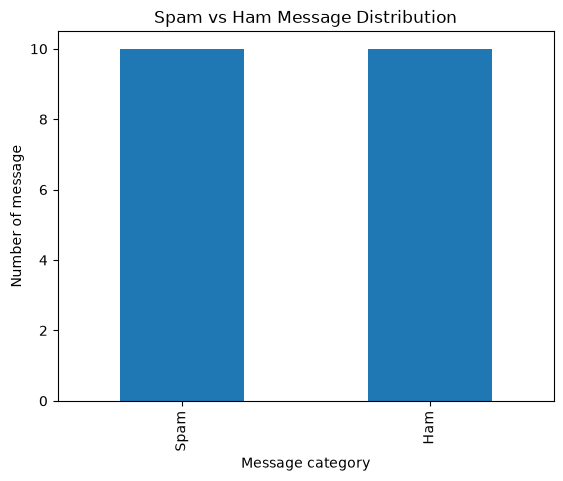

In [92]:
y.value_counts().plot(kind="bar")

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message category")
plt.ylabel("Number of message")

plt.savefig("Spam vs Ham Message Distribution.png", dpi=300, bbox_inches="tight")

plt.show()

SAVING MY AI TRAINED MODEL

In [93]:
import joblib

joblib.dump(model, "Spam_and_ham_detector_model.pkl")

print("Ai Trained model has been saved successfully.")

Ai Trained model has been saved successfully.


In [94]:
import joblib

joblib.dump(model, "tfidf_vectorizer.pkl")

print("TF-IDF Vectorizer has been saved successfully.")

TF-IDF Vectorizer has been saved successfully.


In [95]:
import os 

print("Model saved:", os.path.exists("Spam_and_ham_detector_model.pkl"))
print("Vectorizer saved:", os.path.exists("tfidf_vectorizer.pkl"))

Model saved: True
Vectorizer saved: True


LOAD MY SAVED AI SPAM AND HAM DETECTOR

In [96]:
loaded_model = joblib.load("Spam_and_ham_detector_model.pkl")

loaded_model = joblib.load("tfidf_vectorizer.pkl")

print("Ai Spam Detector loaded sucessfully")

Ai Spam Detector loaded sucessfully


TEST MY MODEL LOADED MESSAGE

In [97]:
message = ["Congratulation! you have a won a free cash prize click here to claim your reward now."]

message_vector = loaded_vectorizer.transform(message)

prediction = loaded_model.predict(message_vector)

if prediction[0].lower() == "spam":
    print("Prediction: SPAM")
    
else:
    print("Prediction: HAM")    

Prediction: SPAM


In [98]:
print("Model classes:", loaded_model.classes_)
print("Actual prediction:", prediction)

Model classes: ['Ham' 'Spam']
Actual prediction: ['Spam']


In [99]:
message = ["Hello, how are you doing today mr micheal."]

message_vector = loaded_vectorizer.transform(message)

prediction = loaded_model.predict(message_vector)

print("Prediction:", prediction[0])

Prediction: Ham


CREATING A REUSABLE FUNCTION FOR MY MODEL

In [100]:
def check_message(message):
    message_vector = loaded_vectorizer.transform([message])
    prediction = loaded_model.predict(message_vector)
    
    print("Message:", message)
    print("Prediction:", prediction[0].upper())

TEST MY PREDICTION FUNCTIION

In [101]:
check_message("Congratulation! you have a free cash prize. click here to claim your reward")

Message: Congratulation! you have a free cash prize. click here to claim your reward
Prediction: SPAM


In [102]:
check_message("Hello! mike, how are you doing today")

Message: Hello! mike, how are you doing today
Prediction: HAM


ADD A CONFIDENCE SCORE TO MY MODEL

In [103]:
def check_message(message):
    message_vector = loaded_vectorizer.transform([message])

    prediction = loaded_model.predict(message_vector)

    probabilities = loaded_model.predict_proba(message_vector)

    class_index = list(loaded_model.classes_).index(prediction[0])

    confidence = probabilities[0][class_index] * 100

    print("Message:", message)
    print("Prediction:", prediction[0].upper())
    print("Confidence:", round(confidence, 2), "%")

EXAMINE THE PREDICTION PROBABILITIES

In [104]:
message = ["Congratulations! You have won a free cash prize. Click here to claim it."]

message_vector = loaded_vectorizer.transform(message)

probabilities = loaded_model.predict_proba(message_vector)

for category, probability in zip(loaded_model.classes_, probabilities[0]):
    print(category, ":", round(probability * 100, 2), "%")

Ham : 21.87 %
Spam : 78.13 %


CHECKING MY PROBABILITIES FUNCTION TODAY

In [105]:
message = ["Congratulations! You have won a free cash prize. Click here to claim it."]

message_vector = loaded_vectorizer.transform(message)

prediction = loaded_model.predict(message_vector)

probabilities = loaded_model.predict_proba(message_vector)

print("Prediction:", prediction[0])
print("Classes:", loaded_model.classes_)
print("Probabilities:", probabilities[0])

Prediction: Spam
Classes: ['Ham' 'Spam']
Probabilities: [0.21871163 0.78128837]


In [106]:
def check_message(message):
    message_vector = loaded_vectorizer.transform([message])

    prediction = loaded_model.predict(message_vector)

    probabilities = loaded_model.predict_proba(message_vector)

    class_index = list(loaded_model.classes_).index(prediction[0])

    confidence = probabilities[0][class_index] * 100

    print("Message:", message)
    print("Prediction:", prediction[0].upper())
    print("Confidence:", round(confidence, 2), "%")

In [107]:
check_message("You have won a free iphone claim your prize now?")

Message: You have won a free iphone claim your prize now?
Prediction: SPAM
Confidence: 83.95 %


In [108]:
check_message("URGENT! you have won a lottery tickek. click on the link below to claim your ticket now.")

Message: URGENT! you have won a lottery tickek. click on the link below to claim your ticket now.
Prediction: SPAM
Confidence: 77.45 %


In [109]:
check_message("Good MOrning! how was your night my love??")

Message: Good MOrning! how was your night my love??
Prediction: HAM
Confidence: 56.15 %


MY FINAL PROJECT VERIFICATION


In [110]:
print("Model loaded:", loaded_model is not None)
print("vectorizer loaded:", loaded_vectorizer is not None)
print ("Prediction Function available:", callable(check_message))

Model loaded: True
vectorizer loaded: True
Prediction Function available: True


ORGANIZING MY PROJECT

In [111]:
import os 

for file in os.listdir():
    print(file)

Ai_spam_detector.ipynb
classification_report.txt
README.md
requirement.txt
Spam vs Ham Message Distribution.png
Spam_and_ham_detector_model.pkl
Spam_detection_history.csv
spam_detection_statistics.png
spam_detector_model.pkl
spam_vectorizer.pkl
tfidf_vectorizer.pkl


CREATE MY PROJECT README

In [112]:
readme = """
# AI Spam Detector

## Project Overview
This project uses Machine Learning to classify text messages
as Spam or Ham (Not Spam).

## Technologies Used
- Python
- Pandas
- Scikit-learn
- TF-IDF Vectorizer
- Multinomial Naive Bayes
- Matplotlib
- Joblib

## Project Features
- Spam and Ham message classification
- Text processing using TF-IDF
- Prediction confidence scores
- Saved and reusable trained model

## Model Files
- spam_detector_model.pkl
- tfidf_vectorizer.pkl

## Dataset
The project uses a small dataset containing 20 messages.

## Disclaimer
The model is a beginner learning project and requires
a larger dataset for reliable real-world performance.
"""

with open("README.md", "w") as file:
    file.write(readme)

print("README created successfully!")
print("Author: Nonso Miracle Adubasim")

README created successfully!
Author: Nonso Miracle Adubasim


In [113]:
import os

print("README exists:", os.path.exists("README.md"))

with open ("README.md", "r") as file:
    print(file.read())
print("Author: Nonso Miracle Adubasim")


README exists: True

# AI Spam Detector

## Project Overview
This project uses Machine Learning to classify text messages
as Spam or Ham (Not Spam).

## Technologies Used
- Python
- Pandas
- Scikit-learn
- TF-IDF Vectorizer
- Multinomial Naive Bayes
- Matplotlib
- Joblib

## Project Features
- Spam and Ham message classification
- Text processing using TF-IDF
- Prediction confidence scores
- Saved and reusable trained model

## Model Files
- spam_detector_model.pkl
- tfidf_vectorizer.pkl

## Dataset
The project uses a small dataset containing 20 messages.

## Disclaimer
The model is a beginner learning project and requires
a larger dataset for reliable real-world performance.

Author: Nonso Miracle Adubasim


A RREQUIREMENT FILE YOU CAN USE TO RUN MY PROJECT

In [114]:
requirement = """
pandas
scikit-learn
matplotlib
joblib
"""
with open("requirement.txt", "w") as file:
    file.write(requirement)

print("Requirement file created successfully.")

Requirement file created successfully.


In [115]:
with open("requirement.txt", "r") as file:
    print(file.read())


pandas
scikit-learn
matplotlib
joblib

